Classes: ['ants', 'bees', 'beetle', 'catterpillar', 'earthworms', 'earwig', 'grasshopper', 'moth', 'slug', 'snail', 'wasp', 'weevil']
DeepPestNet Model Loaded


100%|██████████| 172/172 [17:04<00:00,  5.96s/it]


Epoch 1 | Loss 1.4301 | Val Acc 89.95%


100%|██████████| 172/172 [12:49<00:00,  4.47s/it]


Epoch 2 | Loss 0.4055 | Val Acc 95.38%


100%|██████████| 172/172 [11:10<00:00,  3.90s/it]


... (21 outputs left out)

100%|██████████| 172/172 [11:20<00:00,  3.95s/it]


Epoch 14 | Loss 0.0459 | Val Acc 99.93%


100%|██████████| 172/172 [13:22<00:00,  4.66s/it]


Epoch 15 | Loss 0.0327 | Val Acc 100.00%
              precision    recall  f1-score   support

        ants       1.00      1.00      1.00       499
        bees       1.00      1.00      1.00       500
      beetle       1.00      1.00      1.00       416
catterpillar       1.00      1.00      1.00       434
  earthworms       1.00      1.00      1.00       323
      earwig       1.00      1.00      1.00       466
 grasshopper       1.00      1.00      1.00       485
        moth       1.00      1.00      1.00       497
        slug       1.00      1.00      1.00       391
       snail       1.00      1.00      1.00       500
        wasp       1.00      1.00      1.00       498
      weevil       1.00      1.00      1.00       485

    accuracy                           1.00      5494
   macro avg       1.00      1.00      1.00      5494
weighted avg       1.00      1.00      1.00      5494



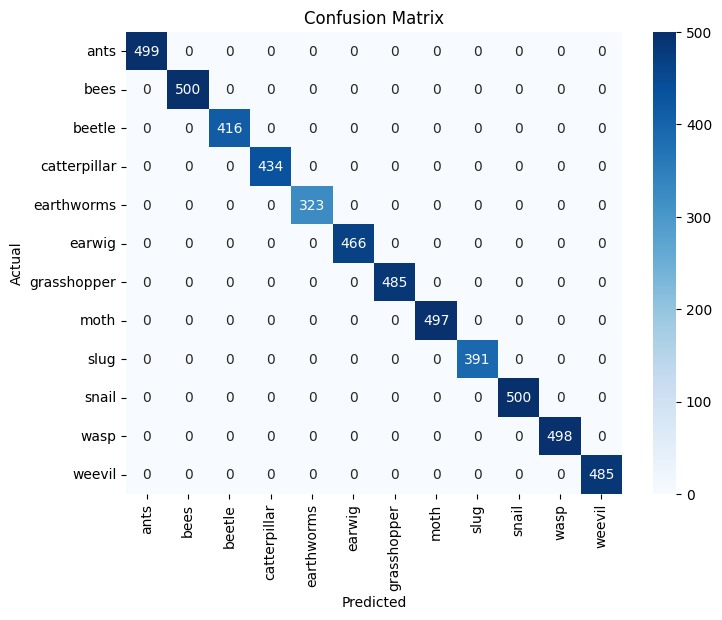

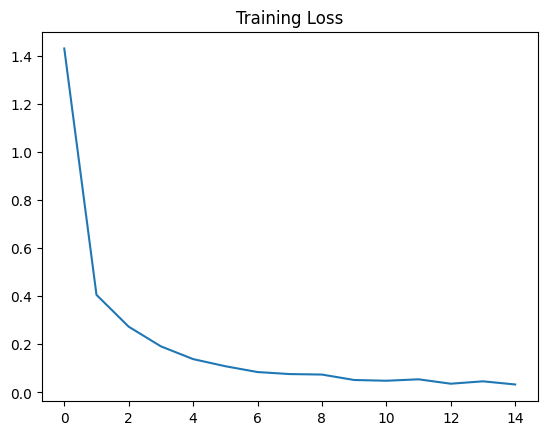

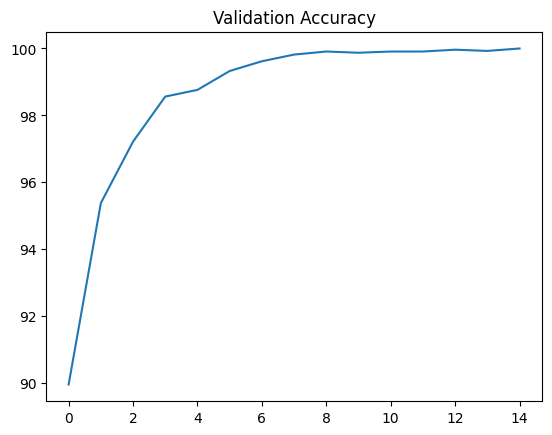

Model Saved


In [1]:
# ============================================================
# DeepPestNet Pest Classification
# EfficientNet-B0 + CBAM Attention
# ============================================================

import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import classification_report, confusion_matrix
from tqdm import tqdm

# ------------------------------------------------------------
# 1️⃣ Setup
# ------------------------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEED = 123
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ------------------------------------------------------------
# 2️⃣ Dataset Paths
# ------------------------------------------------------------

train_dir = "dataset_val"
val_dir = "dataset_val"

# ------------------------------------------------------------
# 3️⃣ Image Transformations
# ------------------------------------------------------------

IMG_SIZE = 224
BATCH = 32

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],
                         [0.229,0.224,0.225])
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],
                         [0.229,0.224,0.225])
])

# ------------------------------------------------------------
# 4️⃣ Load Dataset
# ------------------------------------------------------------

train_ds = datasets.ImageFolder(train_dir, transform=train_tf)
val_ds   = datasets.ImageFolder(val_dir, transform=val_tf)

train_loader = DataLoader(train_ds,
                          batch_size=BATCH,
                          shuffle=True)

val_loader = DataLoader(val_ds,
                        batch_size=BATCH,
                        shuffle=False)

CLASSES = train_ds.classes
print("Classes:", CLASSES)

# ------------------------------------------------------------
# 5️⃣ CBAM Attention Module
# ------------------------------------------------------------

class ChannelAttention(nn.Module):

    def __init__(self, in_channels):
        super().__init__()

        self.fc1 = nn.Linear(in_channels, in_channels//16)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(in_channels//16, in_channels)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        b,c,h,w = x.size()

        avg = torch.mean(x.view(b,c,-1), dim=2)
        mx  = torch.max(x.view(b,c,-1), dim=2)[0]

        att = self.fc2(self.relu(self.fc1(avg))) + \
              self.fc2(self.relu(self.fc1(mx)))

        att = self.sigmoid(att).unsqueeze(2).unsqueeze(3)

        return x * att


class SpatialAttention(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv = nn.Conv2d(2,1,7,padding=3)
        self.sigmoid = nn.Sigmoid()

    def forward(self,x):

        avg = torch.mean(x, dim=1, keepdim=True)
        mx  = torch.max(x, dim=1, keepdim=True)[0]

        att = torch.cat([avg,mx], dim=1)

        att = self.sigmoid(self.conv(att))

        return x * att


class CBAM(nn.Module):

    def __init__(self, channels):
        super().__init__()

        self.ca = ChannelAttention(channels)
        self.sa = SpatialAttention()

    def forward(self,x):

        x = self.ca(x)
        x = self.sa(x)

        return x

# ------------------------------------------------------------
# 6️⃣ DeepPestNet Model
# ------------------------------------------------------------

base = models.efficientnet_b0(weights="DEFAULT")

base.classifier = nn.Identity()

class DeepPestNet(nn.Module):

    def __init__(self, base_model, num_classes):

        super().__init__()

        self.backbone = base_model

        self.att = CBAM(1280)

        self.fc = nn.Sequential(
            nn.Linear(1280,512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512,num_classes)
        )

    def forward(self,x):

        x = self.backbone.features(x)

        x = self.att(x)

        x = torch.nn.functional.adaptive_avg_pool2d(x,(1,1))

        x = x.flatten(1)

        return self.fc(x)

model = DeepPestNet(base,len(CLASSES)).to(DEVICE)

print("DeepPestNet Model Loaded")

# ------------------------------------------------------------
# 7️⃣ Training Setup
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(model.parameters(),
                        lr=1e-4,
                        weight_decay=1e-4)

EPOCHS = 15

history_loss = []
history_acc = []

# ------------------------------------------------------------
# 8️⃣ Training Loop
# ------------------------------------------------------------

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0

    for images,labels in tqdm(train_loader):

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs,labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss/len(train_loader)

    history_loss.append(train_loss)

    # validation

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images,labels in val_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            preds = model(images).argmax(1)

            correct += (preds==labels).sum().item()

            total += labels.size(0)

    acc = 100 * correct/total

    history_acc.append(acc)

    print(f"Epoch {epoch+1} | Loss {train_loss:.4f} | Val Acc {acc:.2f}%")

# ------------------------------------------------------------
# 9️⃣ Evaluation
# ------------------------------------------------------------

y_true = []
y_pred = []

model.eval()

with torch.no_grad():

    for images,labels in val_loader:

        images = images.to(DEVICE)

        preds = model(images).argmax(1).cpu().numpy()

        y_pred.extend(preds)
        y_true.extend(labels.numpy())

print(classification_report(y_true,y_pred,target_names=CLASSES))

cm = confusion_matrix(y_true,y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=CLASSES,
            yticklabels=CLASSES)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

# ------------------------------------------------------------
# 🔟 Training Graphs
# ------------------------------------------------------------

plt.plot(history_loss)
plt.title("Training Loss")
plt.show()

plt.plot(history_acc)
plt.title("Validation Accuracy")
plt.show()

# ------------------------------------------------------------
# Save Model
# ------------------------------------------------------------

torch.save(model.state_dict(),"deeppestnet_model.pth")

print("Model Saved")